# Evaluating generative models of zebrafish bouts

A **model-agnostic** walkthrough that answers two questions and lets you rank any
generative bout model (the three HMMs today; autoregressive ML models later):

1. **Is per-fish (leave-fish-out) cross-validation legitimate?** &mdash; Part 1.
2. **Which model is best?** &mdash; via two complementary metrics:
   - **Metric A** &mdash; held-out predictive likelihood (continuous turn-angle density): *predictability*.
   - **Metric B** &mdash; do free-run samples look like real behaviour: *generative fidelity*.

Design decisions (locked): continuous-angle density in nats/bout for Metric A; turn
channel for likelihood, timing/distance only in Metric B; **leave-3-fish-out, 5
stratified folds** (each fish tested once). Everything that could leak is computed on
the training fold only. Full rationale: `.claude/plans/i-want-you-to-velvet-wilkinson.md`.

> To add YOUR autoregressive model: implement the four-method adapter in the last
> section (`fit / score / sample`) and drop it into the same `model_factories` list.
> No metric code changes.

## 0&nbsp;&nbsp;Setup and data

In [1]:
import sys; sys.path.insert(0, '../scripts'); sys.path.insert(0, 'scripts')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import evaluate as E, generative_metrics as GM, exchangeability as X
import fit_hmm as H, fit_hmm_stim as S

BOUTS = 'data/bouts_GsizeMotionSingle.csv'
try:
    df = E.load_bouts(BOUTS)
except FileNotFoundError:
    df = E.load_bouts('../' + BOUTS)
records = E.build_records(df, min_len=10)   # abs_dict/roi optional (rich model)
print(f'{len(records)} fish; bouts/fish:')
pd.Series({f: r.n for f, r in sorted(records.items())}, name='n_bouts').to_frame().T

15 fish; bouts/fish:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
n_bouts,4272,5273,5526,4816,3258,6686,3137,6378,3199,4550,3129,6143,5674,3824,4725


Each fish is one long ordered bout sequence. The modeled observable is the signed
reorientation angle `dtheta_deg`; the discrete symbol is Forward / Left / Right
(threshold &plusmn;10&deg;). A moving stimulus is present on a minority of bouts:

In [2]:
frac_move = np.mean(np.concatenate([r.moving for r in records.values()]))
sym = np.concatenate([r.symbol for r in records.values()])
print('moving-stimulus bouts: %.1f%%' % (100*frac_move))
print('symbol fractions  F/L/R: %.3f / %.3f / %.3f' % tuple((sym==k).mean() for k in range(3)))

moving-stimulus bouts: 36.4%
symbol fractions  F/L/R: 0.111 / 0.449 / 0.440


## 1&nbsp;&nbsp;Correctness check (does the scorer compute the right likelihood?)

The per-bout predictive log-density must sum to the exact joint log-likelihood from
the model's own scaled forward&ndash;backward, and reproduce each stored model's
`loglik`. `max_abs_diff` should be ~0.

In [3]:
import os
def _p(rel):
    return rel if os.path.exists(rel) else '../' + rel

In [4]:
spont = H.load_hmm(_p('data/hmm_GsizeMotionSingle.npz'))
simple = S.load_model(_p('data/hmm_stim_GsizeMotionSingle.npz'))
E.identity_check(records, spont_model=spont, simple_model=simple).round(6)

,model,max_abs_diff,total_loglik,stored_loglik
0,spontaneous,0.0,-384260.436459,-384260.436460
1,simple_stim,0.0,-383457.138109,-383457.138564


## 2&nbsp;&nbsp;Part&nbsp;1 &mdash; Is leave-fish-out CV legitimate?

LOFO does not need the fish to be identical; it needs the model **ranking** to be
stable across fish. We characterise heterogeneity (ICC, transition homogeneity,
clustering), measure the cost of pooling (pooling gap, learning curve), and &mdash;
after Metric A &mdash; check rank stability directly.

### 2.1&nbsp;&nbsp;Between- vs within-fish variance (ICC)
Contiguous within-fish blocks. ICC&nbsp;&lt;0.3 &asymp; exchangeable for that stat;
&gt;0.6 = strong individuality.

,statistic,icc,interpretation
0,forward_fraction,0.835,strong-individuality
1,abs_dtheta_median,0.796,strong-individuality
2,bout_rate_hz,0.893,strong-individuality
3,lr_bias,0.701,strong-individuality
4,turn_stay,0.729,strong-individuality
5,p_ff,0.574,moderate


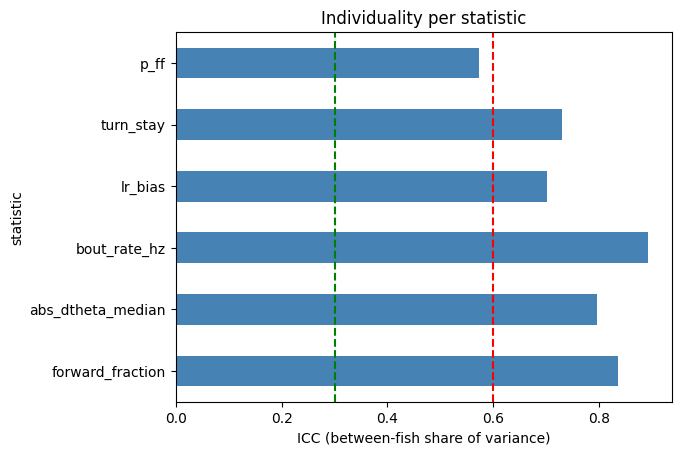

In [5]:
icc = X.icc_table(records, n_blocks=8)
display(icc.round(3))
ax = icc.set_index('statistic')['icc'].plot.barh(color='steelblue')
ax.axvline(0.3, ls='--', c='green'); ax.axvline(0.6, ls='--', c='red')
ax.set_xlabel('ICC (between-fish share of variance)'); ax.set_title('Individuality per statistic'); plt.show()

### 2.2&nbsp;&nbsp;Transition-matrix homogeneity vs a within-fish null
Between-fish Jensen&ndash;Shannon of the F/L/R transition matrices, calibrated
against the split-half within-fish JS. A ratio near 1 means transition structure is
effectively shared (effect size, not a p-value &mdash; with 70k bouts any &chi;&sup2; is significant).

between_mean     0.0136
between_median   0.0095
within_mean      0.0031
within_median    0.0024
ratio_mean       4.3537
ratio_median     3.8715


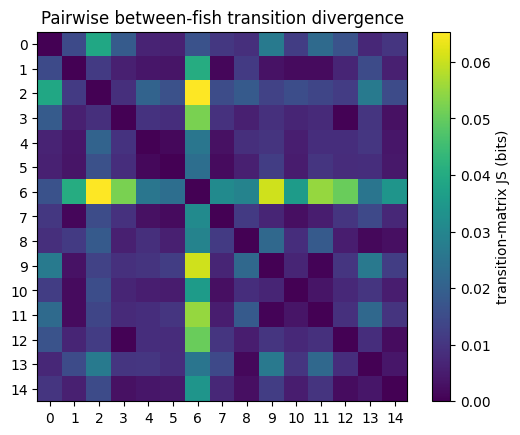

In [6]:
summ, D, fids = X.transition_homogeneity(records)
for k, v in summ.items(): print(f'{k:16s} {v:.4f}')
im = plt.imshow(D, cmap='viridis'); plt.colorbar(im, label='transition-matrix JS (bits)')
plt.xticks(range(len(fids)), fids); plt.yticks(range(len(fids)), fids)
plt.title('Pairwise between-fish transition divergence'); plt.show()

### 2.3&nbsp;&nbsp;Do fish form behavioural clusters? (&rarr; stratify folds)

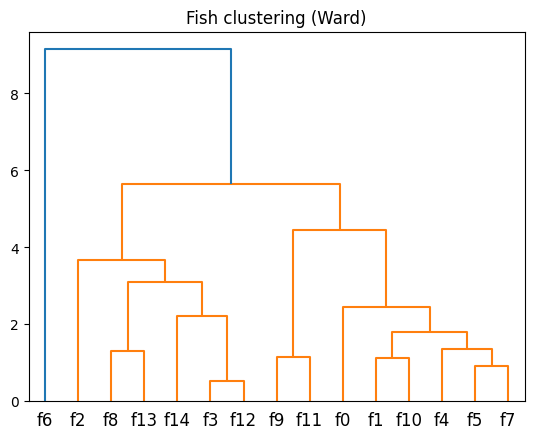

cluster labels: {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 2, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1}


,forward_fraction,abs_dtheta_median,bout_rate_hz,lr_bias,turn_stay,p_ff
0,0.181,33.690,0.625,-0.070,0.493,0.190
1,0.092,37.057,0.769,-0.057,0.461,0.121
2,0.064,45.000,0.833,0.150,0.431,0.085
3,0.080,40.938,0.698,0.060,0.534,0.104
4,0.133,31.891,0.732,-0.089,0.456,0.145
5,0.138,35.134,0.833,-0.013,0.445,0.143
6,0.277,23.682,1.500,-0.020,0.368,0.337
7,0.116,35.741,0.937,-0.062,0.441,0.132
8,0.130,37.405,0.857,0.119,0.523,0.171
9,0.062,51.340,0.667,-0.117,0.466,0.092


In [7]:
labels, Z, feat = X.cluster_fish(records, n_clusters=2)
from scipy.cluster.hierarchy import dendrogram
dendrogram(Z, labels=[f'f{f}' for f in feat.index]); plt.title('Fish clustering (Ward)'); plt.show()
print('cluster labels:', labels)
display(feat.round(3))

### 2.4&nbsp;&nbsp;Pooling gap &mdash; personalized vs pooled (data-matched)
`gap_matched` compares *training on the fish itself* vs *training on one other fish*
(same data volume): the pure cost of individuality, in nats/bout. Small &rArr; fish
exchangeable. **Slow** &mdash; 15 full-data refits; both sides share the same `max_iter`
so the gap stays fair even under-converged. Bump `max_iter` for the final run.

,fish_id,n_test,personalized,pooled_full,pooled_matched,gap_full,gap_matched
0,0,2136,-5.2764,-5.3234,-5.3672,0.0471,0.0909
1,1,2637,-5.2768,-5.3094,-5.4135,0.0326,0.1367
2,2,2763,-5.3647,-5.4152,-5.4827,0.0504,0.1180
3,3,2408,-5.4122,-5.4227,-5.4594,0.0105,0.0473
4,4,1629,-5.3563,-5.3882,-5.3972,0.0320,0.0409
5,5,3343,-5.2708,-5.3104,-5.2820,0.0396,0.0112
6,6,1569,-5.3279,-5.3807,-5.4139,0.0529,0.0861
7,7,3189,-5.3160,-5.3320,-5.3332,0.0160,0.0172
8,8,1600,-5.5188,-5.5477,-5.6598,0.0290,0.1410
9,9,2275,-5.5510,-5.5980,-5.5941,0.0470,0.0430


median gap_full = 0.0326  |  median gap_matched = 0.0861  nats/bout


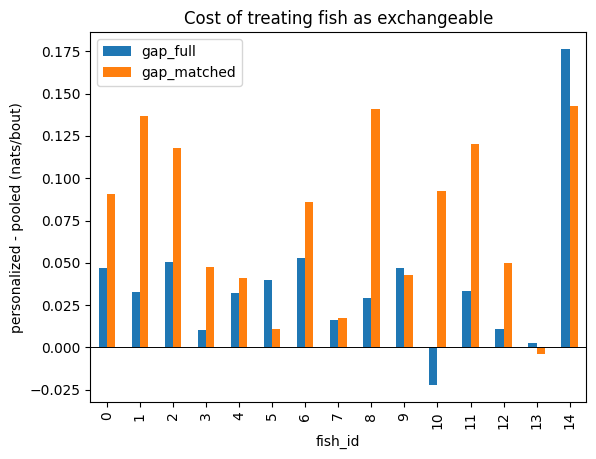

In [8]:
pg = X.pooling_gap(records, model_factory=lambda: E.SpontaneousHMM(restarts=1, max_iter=30), seed=0)
display(pg.round(4))
print('median gap_full = %.4f  |  median gap_matched = %.4f  nats/bout'
      % (pg.gap_full.median(), pg.gap_matched.median()))
pg.set_index('fish_id')[['gap_full','gap_matched']].plot.bar(); plt.ylabel('personalized - pooled (nats/bout)')
plt.axhline(0, c='k', lw=.7); plt.title('Cost of treating fish as exchangeable'); plt.show()

### 2.5&nbsp;&nbsp;Learning curve vs number of training fish
A plateau before 12 fish means the population is well covered &mdash; adding fish
stops helping, so LOFO is near its asymptote.

,n_train_fish,mean,std,count
0,1,-5.4904,0.0000,3
1,2,-5.4674,0.0255,3
2,4,-5.4529,0.0039,3
3,8,-5.4482,0.0016,3
4,12,-5.4454,0.0000,3


held-out fish: [np.int64(8), np.int64(7), np.int64(11)]


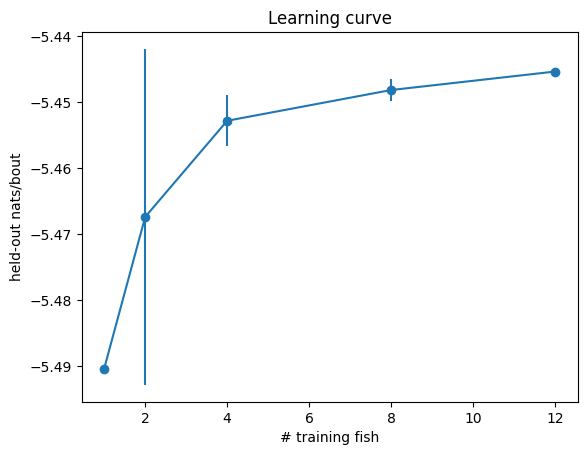

In [9]:
raw, agg, holdout = X.learning_curve(records, sizes=(1,2,4,8,12), n_holdout=3, n_draws=3,
                                     model_factory=lambda: E.SpontaneousHMM(restarts=1, max_iter=30))
display(agg.round(4)); print('held-out fish:', holdout)
plt.errorbar(agg.n_train_fish, agg['mean'], yerr=agg['std'], marker='o')
plt.xlabel('# training fish'); plt.ylabel('held-out nats/bout'); plt.title('Learning curve'); plt.show()

## 3&nbsp;&nbsp;Metric&nbsp;A &mdash; predictive likelihood (which model predicts best?)

Leave-3-fish-out CV. Primary = held-out **density bits/bout** of the turn angle
(lower = better); secondary = **3-symbol** bits/bout (universal for categorical
models). Baselines: `marginal_density` (no dynamics), `unigram`, `bigram`.
Folds are **stratified** by the clusters found above.

In [10]:
strata = X.strata_from_clusters(records, n_clusters=2)
folds = E.make_folds(sorted(records), n_folds=5, strata=strata, seed=0)
print('fold test groups:', [t for _, t in folds])
# restarts=1, capped max_iter keep the walkthrough responsive; raise both for final numbers
facs = E.default_model_factories(restarts=1, max_iter=120, include_rich=False)
likA = E.cross_validate_likelihood(records, facs, folds, verbose=True)
likA = E.add_skill_scores(likA)
likA.head()

fold test groups: [[3, 8, 10], [2, 13, 14], [0, 9, 11], [1, 5, 12], [4, 6, 7]]
  fold 0: trained on 12 fish, scored [3, 8, 10]
  fold 1: trained on 12 fish, scored [2, 13, 14]
  fold 2: trained on 12 fish, scored [0, 9, 11]
  fold 3: trained on 12 fish, scored [1, 5, 12]
  fold 4: trained on 12 fish, scored [4, 6, 7]


,fish_id,model,n_bouts,nats_per_bout,bits_per_bout,nats_stim,nats_nostim,n_stim,symbol_nats_per_bout,symbol_bits_per_bout,symbol_perplexity,fold,density_skill_bits,symbol_skill_bits
0,3,marginal_density,4816,-5.463407,7.882031,-5.578228,-5.393533,1822.0,-0.933250,1.346395,2.542760,0,0.0,-0.025399
1,8,marginal_density,3199,-5.544196,7.998584,-5.618104,-5.502716,1150.0,-0.992021,1.431184,2.696679,0,0.0,-0.012782
2,10,marginal_density,3129,-5.495133,7.927801,-5.432188,-5.537567,1260.0,-0.945376,1.363890,2.573782,0,0.0,-0.017705
3,3,unigram,4816,NaN,NaN,NaN,NaN,NaN,-0.923609,1.332487,2.518364,0,NaN,-0.011491
4,8,unigram,3199,NaN,NaN,NaN,NaN,NaN,-0.993005,1.432604,2.699334,0,NaN,-0.014201


### 3.1&nbsp;&nbsp;Headline: density bits/bout across fish (mean &plusmn; fish-level bootstrap CI)

,model,metric,mean,mean_lo,mean_hi,median,n_fish
2,simple_stim,bits_per_bout,7.8570,7.7645,7.9795,7.8074,15
3,spontaneous,bits_per_bout,7.8743,7.7828,7.9933,7.8269,15
1,marginal_density,bits_per_bout,7.8873,7.7916,8.0073,7.8555,15
0,bigram,bits_per_bout,NaN,NaN,NaN,NaN,0
4,unigram,bits_per_bout,NaN,NaN,NaN,NaN,0


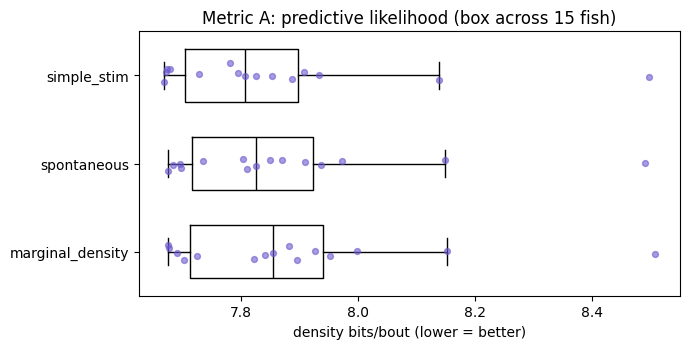

In [11]:
sumA = E.summarize(likA, metric='bits_per_bout')
display(sumA.round(4))
# Box plot of the per-fish density bits/bout for each model (15 fish per box),
# instead of a bar of the mean. Models ordered best (lowest) first; per-fish
# points overlaid. The mean +/- fish-level bootstrap CI is in the table above.
order = sumA.dropna(subset=['mean']).sort_values('mean')['model'].tolist()
data = [likA.loc[likA.model == m, 'bits_per_bout'].dropna().to_numpy() for m in order]
fig, ax = plt.subplots(figsize=(7, 0.7 * len(order) + 1.5))
ax.boxplot(data, vert=False, showfliers=False, widths=0.6,
           medianprops=dict(color='black'))
rng = np.random.default_rng(0)
for i, dv in enumerate(data):
    ax.scatter(dv, rng.normal(i + 1, 0.06, len(dv)), s=18, color='slateblue', alpha=0.6, zorder=3)
ax.set_yticks(range(1, len(order) + 1)); ax.set_yticklabels(order)
ax.set_xlabel('density bits/bout (lower = better)')
ax.set_title('Metric A: predictive likelihood (box across 15 fish)')
ax.invert_yaxis()   # best model on top
plt.tight_layout(); plt.show()

### 3.2&nbsp;&nbsp;Skill score vs the marginal baseline (bits saved/bout by the dynamics)

In [12]:
sk = E.summarize(likA, metric='density_skill_bits')
display(sk.dropna(subset=['mean']).round(4))
print('symbol-track skill vs bigram:')
display(E.summarize(likA, metric='symbol_skill_bits').dropna(subset=['mean']).round(4))

,model,metric,mean,mean_lo,mean_hi,median,n_fish
1,marginal_density,density_skill_bits,0.0000,0.0000,0.0000,0.0000,15
3,spontaneous,density_skill_bits,0.0130,0.0049,0.0211,0.0163,15
2,simple_stim,density_skill_bits,0.0303,0.0197,0.0410,0.0339,15


symbol-track skill vs bigram:


,model,metric,mean,mean_lo,mean_hi,median,n_fish
1,marginal_density,symbol_skill_bits,-0.0089,-0.0168,-0.0005,-0.0128,15
4,unigram,symbol_skill_bits,-0.0071,-0.0119,-0.0027,-0.0076,15
0,bigram,symbol_skill_bits,0.0000,0.0000,0.0000,0.0000,15
3,spontaneous,symbol_skill_bits,0.0017,-0.0002,0.0033,0.0018,15
2,simple_stim,symbol_skill_bits,0.0179,0.0126,0.0233,0.0188,15


### 3.3&nbsp;&nbsp;Stimulus stratum &mdash; the stimulus models must earn their keep where the stimulus is present
Only a minority of bouts have a moving stimulus, so a real following effect is
diluted in the overall average. Compare nats/bout on stimulus-present vs -absent bouts.

,nats_per_bout,nats_stim,nats_nostim
model,,,
marginal_density,-5.4671,-5.5217,-5.4355
simple_stim,-5.4461,-5.4800,-5.4265
spontaneous,-5.4581,-5.5112,-5.4273


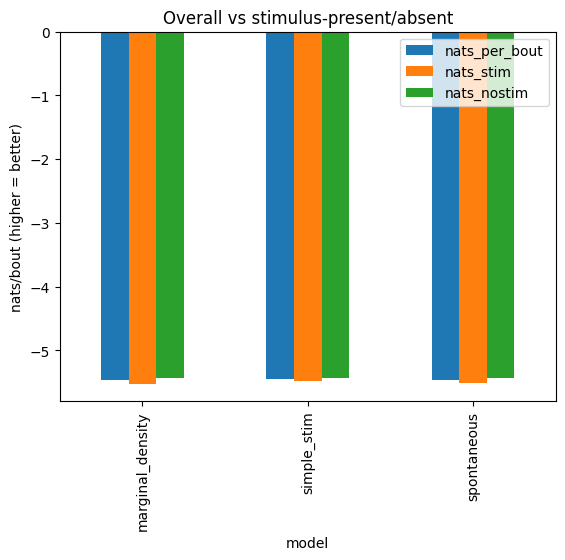

In [13]:
strat = likA.dropna(subset=['nats_stim']).groupby('model')[['nats_per_bout','nats_stim','nats_nostim']].mean()
display(strat.round(4))
strat.plot.bar(); plt.ylabel('nats/bout (higher = better)'); plt.title('Overall vs stimulus-present/absent'); plt.show()

### 3.4&nbsp;&nbsp;Paired model comparison + rank stability (Part&nbsp;1A)
The 5 folds collapse into ONE paired test over the 15 held-out fish. High
sign-agreement (`prefer_a` near N) means the ranking is trustworthy regardless of
individuality &mdash; this is what licenses LOFO.

,model_a,model_b,metric,n_fish,prefer_a,prefer_b,ties,median_delta,delta_lo,delta_hi,wilcoxon_p,sign_test_p
0,simple_stim,spontaneous,nats_per_bout,15,14,1,0,0.0136,0.0074,0.0164,0.0003,0.0010
1,spontaneous,marginal_density,nats_per_bout,15,13,2,0,0.0113,0.0034,0.0126,0.0103,0.0074
2,bigram,unigram,nats_per_bout,0,0,0,0,NaN,NaN,NaN,NaN,NaN


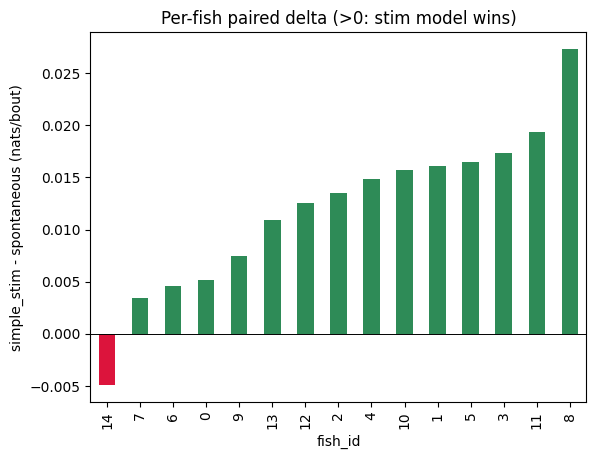

In [14]:
pairs = [('simple_stim','spontaneous'), ('spontaneous','marginal_density'), ('bigram','unigram')]
rs = X.rank_stability(likA, pairs, metric='nats_per_bout', higher_better=True)
display(rs.round(4))
# per-fish paired deltas for the headline pair
a = likA[likA.model=='simple_stim'].set_index('fish_id')['nats_per_bout']
b = likA[likA.model=='spontaneous'].set_index('fish_id')['nats_per_bout']
delta = (a-b).sort_values()
delta.plot.bar(color=['crimson' if v<0 else 'seagreen' for v in delta]); plt.axhline(0,c='k',lw=.7)
plt.ylabel('simple_stim - spontaneous (nats/bout)'); plt.title('Per-fish paired delta (>0: stim model wins)'); plt.show()

## 4&nbsp;&nbsp;Metric&nbsp;B &mdash; generative fidelity (do free-run samples look real?)

Needed IN ADDITION to Metric A: a model can predict each next bout well yet drift
over long rollouts. We teacher-force each held-out fish's real stimulus stream, draw
`R` rollouts matched to the real bout count, and compare distributions/structure.

*(Refits the models per fold and samples R&times;15 fish &mdash; a few minutes; raise `R` for tighter Monte-Carlo CIs.)*

In [15]:
panel, wins = GM.cross_validate_generative(records, facs, folds, R=12, W=60, verbose=True)
sumB = GM.summarize_panel(panel)
cols = ['model','abs_dtheta_w1','symbol_js','dt_w1','dist_w1','trans_js','acf_l2','runlen_w1','tuning_mse','following_gap']
display(sumB[[c for c in cols if c in sumB.columns]].round(4))

  fold 0: generative panel for test fish [3, 8, 10]
  fold 1: generative panel for test fish [2, 13, 14]
  fold 2: generative panel for test fish [0, 9, 11]
  fold 3: generative panel for test fish [1, 5, 12]
  fold 4: generative panel for test fish [4, 6, 7]


,model,abs_dtheta_w1,symbol_js,dt_w1,dist_w1,trans_js,acf_l2,runlen_w1,tuning_mse,following_gap
0,simple_stim,6.7773,0.0063,0.8416,2.6575,0.0078,0.0493,0.1384,0.0059,0.0357
1,spontaneous,6.7611,0.0063,0.8450,2.6603,0.0077,0.0517,0.1379,0.0208,0.1231


### Eyeball a single rollout &mdash; what is each model actually doing?
Before the aggregate distances, look at ONE free-run rollout next to the real fish.
Six views of the same sequence: the reconstructed (x,y) path (`H.reconstruct_xy`
from `dtheta` + `distance_px`), `dtheta` vs time, cumulative heading (systematic
left/right winding), x&nbsp;vs&nbsp;t and y&nbsp;vs&nbsp;t (dispersion rate), and a running mean of
`|dtheta|` (turn-magnitude stationarity / drift). Time axis `t = cumsum(dt_s)`.
Models are fit leave-this-fish-out so nothing leaks. Mismatches here tell you *which*
feature is off before the numbers do.

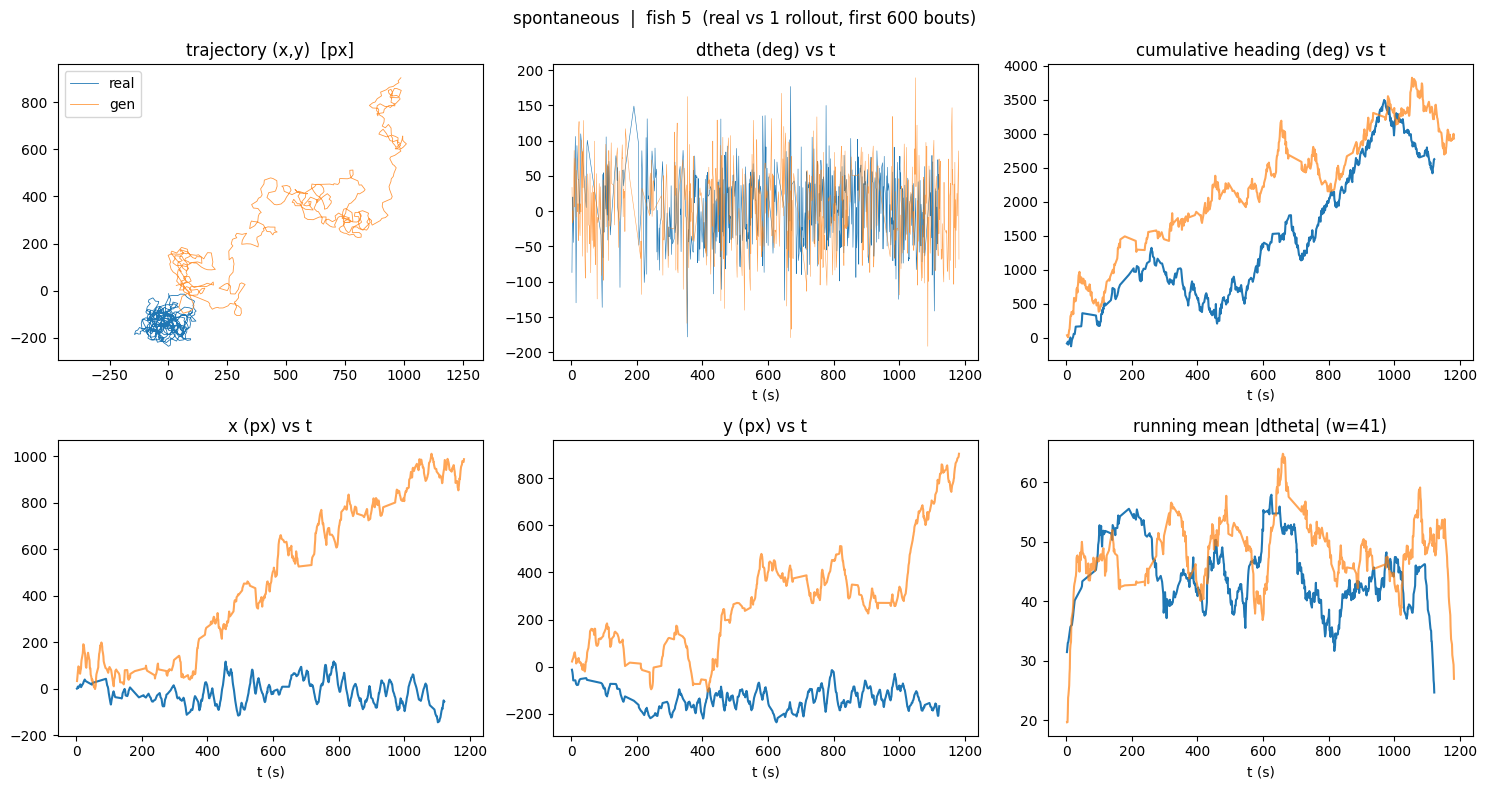

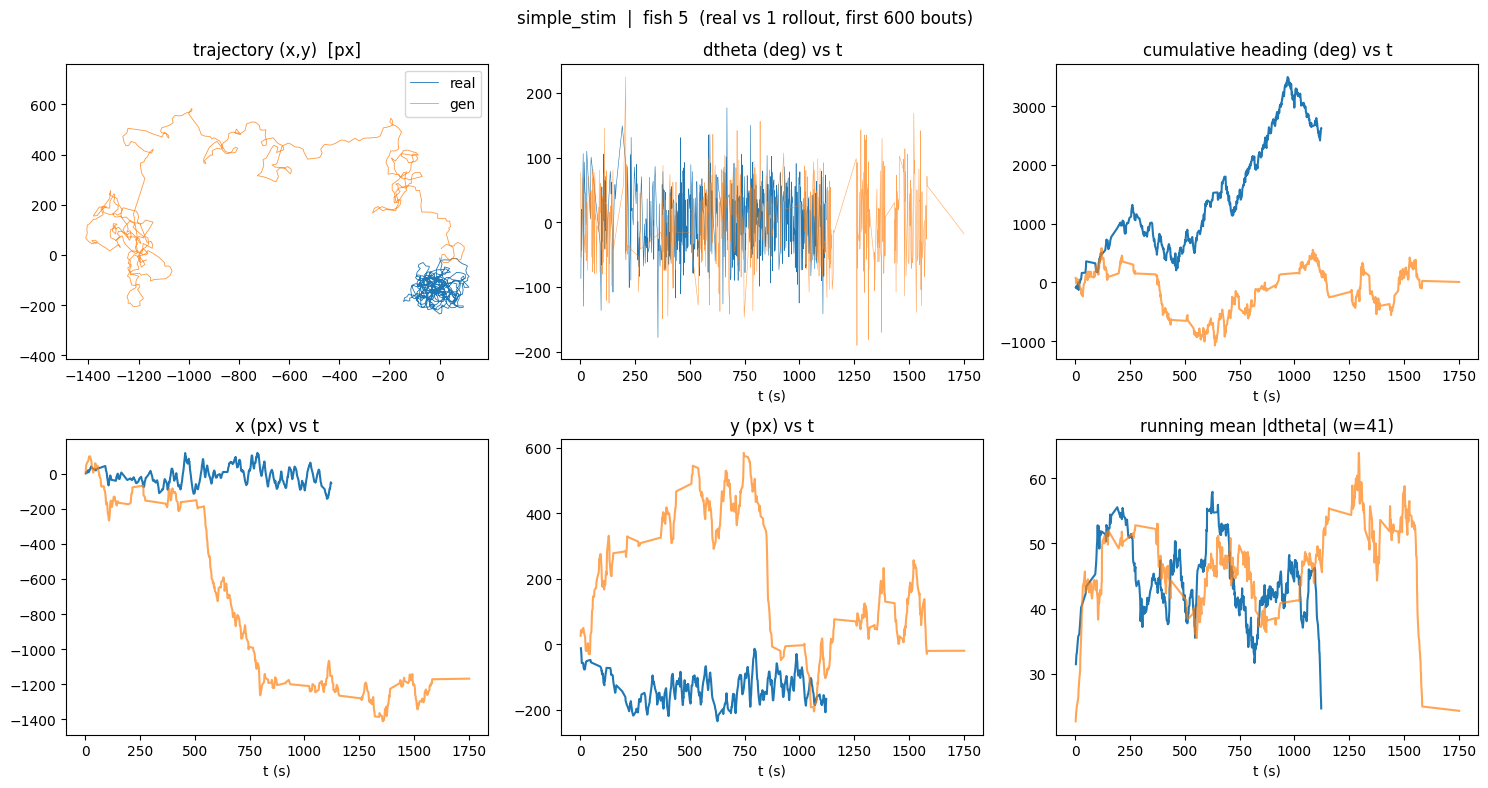

In [16]:
def eyeball_rollout(model, rec, rng, nmax=600, smooth=41, figtitle=None):
    """Real fish vs ONE free-run rollout (stimulus teacher-forced). 6 panels.
    First `nmax` bouts only (the full path is an unreadable random walk). NaN-safe."""
    g = model.sample(rec, rng)
    def clean(a, fill):
        a = np.asarray(a, float); return np.where(np.isfinite(a), a, fill)
    dt_fill = np.nanmedian(rec.dt_s) if np.isfinite(rec.dt_s).any() else 1.0
    def unpack(dth, dist, dt):
        k = min(nmax, len(dth))
        dth = np.asarray(dth, float)[:k]
        x, y, _ = H.reconstruct_xy(dth, clean(dist, 0.0)[:k])   # distance NaN->0
        return dth, np.cumsum(clean(dt, dt_fill)[:k]), x, y      # dt NaN->median
    r_dth, rt, rx, ry = unpack(rec.dtheta, rec.distance_px, rec.dt_s)
    g_dth, gt, gx, gy = unpack(g['dtheta'], g['distance_px'], g['dt_s'])
    def run(a, w):
        a = np.abs(np.asarray(a, float)); w = max(1, min(w, len(a)))
        return np.convolve(a, np.ones(w) / w, mode='same')
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    ax[0, 0].plot(rx, ry, lw=.6, label='real'); ax[0, 0].plot(gx, gy, lw=.6, alpha=.8, label='gen')
    ax[0, 0].set_title('trajectory (x,y)  [px]'); ax[0, 0].set_aspect('equal', 'datalim'); ax[0, 0].legend()
    ax[0, 1].plot(rt, r_dth, lw=.4); ax[0, 1].plot(gt, g_dth, lw=.4, alpha=.7); ax[0, 1].set_title('dtheta (deg) vs t')
    ax[0, 2].plot(rt, np.cumsum(r_dth)); ax[0, 2].plot(gt, np.cumsum(g_dth), alpha=.7)
    ax[0, 2].set_title('cumulative heading (deg) vs t')
    ax[1, 0].plot(rt, rx); ax[1, 0].plot(gt, gx, alpha=.7); ax[1, 0].set_title('x (px) vs t')
    ax[1, 1].plot(rt, ry); ax[1, 1].plot(gt, gy, alpha=.7); ax[1, 1].set_title('y (px) vs t')
    ax[1, 2].plot(rt, run(r_dth, smooth)); ax[1, 2].plot(gt, run(g_dth, smooth), alpha=.7)
    ax[1, 2].set_title(f'running mean |dtheta| (w={smooth})')
    for a in ax.ravel()[1:]:
        a.set_xlabel('t (s)')
    fig.suptitle(figtitle or f'{model.name}  |  fish {rec.fish_id}  (real vs 1 rollout, first {nmax} bouts)')
    plt.tight_layout(); plt.show()


def _fit_leaveout(factory, records, holdout_fid, cfg=None):
    """Fit a fresh model on all fish EXCEPT holdout_fid (leak-free eyeball)."""
    train = [r for f, r in records.items() if f != holdout_fid]
    m = factory(); m.fit(train, E.make_context(train, cfg or {})); return m


rng = np.random.default_rng(0)
EYE_FID = 5     # a high-bout fish
for fac in [lambda: E.SpontaneousHMM(restarts=1, max_iter=120),
            lambda: E.SimpleStimHMM(restarts=1, max_iter=120)]:
    eyeball_rollout(_fit_leaveout(fac, records, EYE_FID), records[EYE_FID], rng)

### 4.1&nbsp;&nbsp;Turn-sign autocorrelation and run-lengths (rollout-drift detectors)

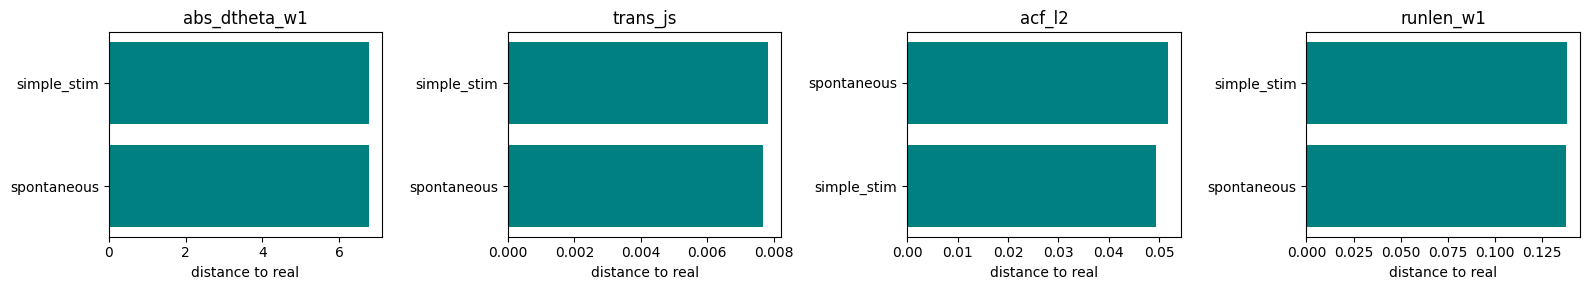

In [17]:
mt = ['abs_dtheta_w1','trans_js','acf_l2','runlen_w1']
fig, axes = plt.subplots(1, len(mt), figsize=(4*len(mt),3))
for ax, m in zip(axes, mt):
    g = panel.groupby('model')[m].mean().sort_values()
    ax.barh(g.index, g.values, color='teal'); ax.set_title(m); ax.set_xlabel('distance to real')
plt.tight_layout(); plt.show()

### 4.2&nbsp;&nbsp;The functional stimulus test: does the model reproduce following?
The spontaneous model ignores the stimulus, so its generated following index should
be ~0; the stimulus models should match the real (positive) following index.

**Moving vs static split.** The following index is now also computed on **static-dot**
bouts (`np.isfinite(stim_angle) & ~moving`). For the current models this is a
**null-check**: the simple/spontaneous drive (`rec.b`) is 0 on static bouts, so
`generated (static) ≈ 0` *by construction* — not a finding. The split becomes useful
for future stimulus-rich models: a positive `real (static)` (fish orient toward
static dots) with `generated (static) ≈ 0` is a documented model deficiency the
metric will expose.

,real (moving),generated (moving),real (static),generated (static)
model,,,,
simple_stim,0.124,0.122,0.055,-0.000
spontaneous,0.124,0.001,0.055,0.001


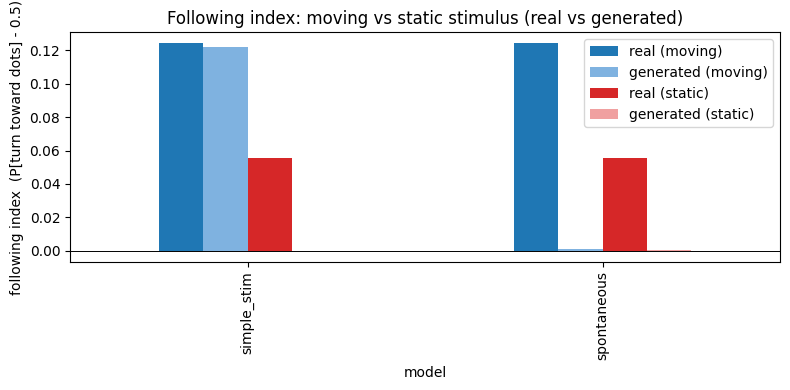

In [18]:
# Following index split by stimulus kind: MOVING dots vs STATIC dots (real vs generated).
cols = ['real_following_index', 'gen_following_index',
        'real_following_index_static', 'gen_following_index_static']
fi = panel.groupby('model')[cols].mean()
fi.columns = ['real (moving)', 'generated (moving)', 'real (static)', 'generated (static)']
display(fi.round(3))
ax = fi.plot.bar(figsize=(8, 4), color=['#1f77b4', '#7fb2e0', '#d62728', '#f0a0a0'])
ax.set_ylabel('following index  (P[turn toward dots] - 0.5)')
ax.axhline(0, c='k', lw=.7)
ax.set_title('Following index: moving vs static stimulus (real vs generated)')
plt.tight_layout(); plt.show()

### 4.3&nbsp;&nbsp;Omnibus: classifier two-sample test (can we tell real from generated?)
GroupKFold **by fish**. AUC 0.5 = indistinguishable (good); &rarr;1 = the model's
samples are detectable.

Two additions:
- **Negative control (real-vs-real).** Each fish's *real* windows are randomly split
  into two halves and fed as the two classes. Both are real, so the AUC should be
  **~0.5** — this confirms the GroupKFold pipeline isn't picking up fish idiosyncrasy
  and inflating the real-vs-generated AUC. It's the floor the real AUC is measured against.
- **Feature importances.** Mean RandomForest impurity importance (over the same
  folds) per feature — *where* the classifier looks to separate real from generated
  (e.g. `|dtheta|` magnitude vs transition structure vs ACF). Read as "which axis the
  samples are least realistic on", not a calibrated effect size (impurity importance
  favours high-variance features).

spontaneous      C2ST AUC = 0.752   neg-control (real-vs-real) AUC = 0.504
simple_stim      C2ST AUC = 0.768   neg-control (real-vs-real) AUC = 0.504


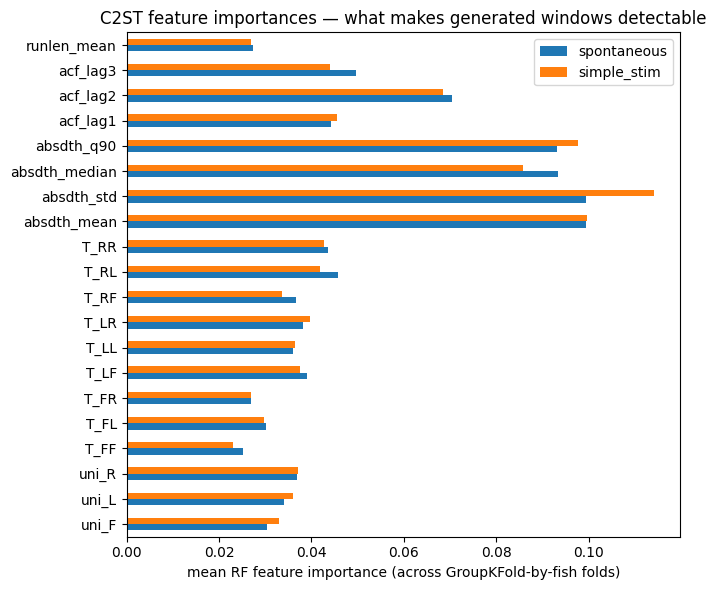

,spontaneous,simple_stim
uni_F,0.030,0.033
uni_L,0.034,0.036
uni_R,0.037,0.037
T_FF,0.025,0.023
T_FL,0.030,0.030
T_FR,0.027,0.027
T_LF,0.039,0.037
T_LL,0.036,0.037
T_LR,0.038,0.040
T_RF,0.037,0.034


In [19]:
imp_by_model = {}
for name, wm in wins.items():
    auc, _ = GM.c2st_auc(wm)
    nc = GM.c2st_negative_control(wm, seed=0)   # real-vs-real; should be ~0.5
    print(f'{name:16s} C2ST AUC = {auc:.3f}   neg-control (real-vs-real) AUC = {nc:.3f}')
    imp_by_model[name] = GM.c2st_importances(wm)

# Which features let the classifier tell generated from real windows?
imp = pd.DataFrame(imp_by_model)                    # 20 features x n_models
ax = imp.plot.barh(figsize=(7, 6))
ax.set_xlabel('mean RF feature importance (across GroupKFold-by-fish folds)')
ax.set_title('C2ST feature importances — what makes generated windows detectable')
plt.tight_layout(); plt.show()
display(imp.round(3))

## 5&nbsp;&nbsp;(Optional) include the rich stimulus model
The rich IO-HMM needs the per-frame `abs_dict.pkl` (963&nbsp;MB) to build its stimulus
features. Load it once, rebuild records WITH features, and add `RichStimHMM` to the
model list. Skip if the file is unavailable or you want a fast pass.

In [20]:
RUN_RICH = False   # set True if abs_dict.pkl is available
if RUN_RICH:
    import pickle
    with open(_p('notebooks/abs_dict.pkl'), 'rb') as fh: abs_dict = pickle.load(fh)
    roi = pd.read_csv(_p('data/data/ROIdef.csv'))
    records_r = E.build_records(df, min_len=10, abs_dict=abs_dict, roi=roi)
    rich = S.load_model_any(_p('data/hmm_stim_rich_GsizeMotionSingle.npz'))
    display(E.identity_check(records_r, rich_model=rich).round(6))
    facs_r = E.default_model_factories(restarts=2, include_rich=True)
    likA_r = E.add_skill_scores(E.cross_validate_likelihood(records_r, facs_r, folds, verbose=True))
    display(E.summarize(likA_r, metric='bits_per_bout').round(4))

## 6&nbsp;&nbsp;Reading the results / adding your own model

**Decision flow.**
1. Part&nbsp;1 licenses LOFO if ICCs are moderate, transition between/within&nbsp;&asymp;1,
   the pooling gap is small, the learning curve plateaus, **and** paired sign-agreement
   is high (&ge;13/15). If fish cluster, keep the stratified folds used above.
2. Rank models by Metric&nbsp;A density bits/bout (paired Wilcoxon + sign test), reading
   the stimulus models mainly on the stimulus-present stratum.
3. Confirm with Metric&nbsp;B: a winner must also produce realistic rollouts (low ACF/
   run-length distance) and reproduce the following curve (low C2ST AUC).

**To add an autoregressive model**, implement this adapter and add it to `facs`:

In [21]:
class MyARModel(E.GenerativeModel):
    name = 'my_ar'
    def fit(self, train_records, ctx):
        # train on [r.dtheta / r.symbol / r.b / r.u_raw for r in train_records]
        return self
    def score(self, rec):
        # continuous head -> logdens (n,) = log p(dtheta_t | past, stim), nats/deg
        # (or categorical head -> symbol_logq (n,3); set has_density=False)
        return dict(logdens=None, symbol_logq=None)
    def sample(self, rec, rng):
        # free-run given rec's stimulus; return dtheta/symbol/dt_s/distance_px
        return dict(dtheta=..., symbol=..., dt_s=..., distance_px=...)
# facs = facs + [lambda: MyARModel()]   # then rerun sections 3 and 4

## 7&nbsp;&nbsp;Quick results — pick models, fetch Metric A + Metric B + C2ST in one table

Self-contained: run **cell 0** (setup) then the two cells below — you do **not** need
to run sections 2–6. Edit `SELECT` to choose models; you get one row per model with
the headline **Metric A** (`bits_per_bout`, `density_skill_bits`, `symbol_bits`), the
full **Metric B** panel (`abs_dtheta_w1 … following_gap`), and the **C2ST AUC** — no
plots, just the dataframe. Models that can't free-run (marginal/unigram/bigram) show
`NaN` for Metric B / AUC. Lower is better everywhere **except** `density_skill_bits`
(higher) and `c2st_auc` (0.5 = indistinguishable = ideal). `n_folds`/`R` default to the
full 5-fold / R=12; pass e.g. `n_folds=2, R=6` for a fast preview.

In [2]:
import time

# ---- model zoo: name -> zero-arg factory. Add your own here. ----
try:
    import fit_MLP as M
    _MLP = {'mlp_basic': lambda: M.MLPDensity(mode='basic', K=5, stim_mode='simple', hidden=64),
            'mlp_full':  lambda: M.MLPDensity(mode='full',  K=5, stim_mode='simple', hidden=64)}
except Exception as _e:                       # torch/fit_MLP not importable -> HMMs only
    _MLP = {}; print('(fit_MLP unavailable, MLP models omitted:', _e, ')')

MODEL_ZOO = {
    'marginal_density': lambda: E.MarginalDensity(),
    'unigram':          lambda: E.UnigramSymbol(),
    'bigram':           lambda: E.BigramSymbol(),
    'spontaneous':      lambda: E.SpontaneousHMM(restarts=1, max_iter=120),
    'simple_stim':      lambda: E.SimpleStimHMM(restarts=1, max_iter=120),
    **_MLP,
    # 'rich_stim':      lambda: E.RichStimHMM(restarts=1),   # needs records built with abs_dict/roi
}
print('available:', list(MODEL_ZOO))

_METRIC_B = ['abs_dtheta_w1', 'symbol_js', 'dt_w1', 'dist_w1', 'trans_js',
             'acf_l2', 'runlen_w1', 'tuning_mse', 'following_gap']


class _ETA:
    """Live one-line progress bar: elapsed + estimated time left, per phase."""
    def __init__(self, phase, width=22):
        self.phase, self.width, self.t0 = phase, width, None

    def __call__(self, done, total, detail=''):
        now = time.time()
        if self.t0 is None:
            self.t0 = now
        el = now - self.t0
        left = el / max(done, 1) * (total - done)
        fill = int(self.width * done / max(total, 1))
        bar = '#' * fill + '.' * (self.width - fill)
        print(f"\r  {self.phase:9s}[{bar}] {done:>2}/{total}  {el:4.0f}s elapsed  ~{left:4.0f}s left   {detail:24s}",
              end=('\n' if done >= total else ''), flush=True)


def quick_results(select, records, n_folds=5, seed=0, R=12, W=60, cfg=None, verbose=False):
    """One row per selected model: Metric A (bits/bout + skills) + Metric B panel
    (abs_dtheta_w1 ... following_gap) + C2ST AUC. Returns (table, likA, panel, wins).
    Prints a live progress bar + ETA for each phase. Baselines that can't free-run
    show NaN for Metric B / AUC. `cfg` caps MLP epochs (default 40)."""
    bad = [m for m in select if m not in MODEL_ZOO]
    if bad:
        raise KeyError(f'unknown models {bad}; available {list(MODEL_ZOO)}')
    cfg = cfg or dict(mlp_epochs=40)
    folds = E.make_folds(sorted(records), n_folds=n_folds, seed=seed)
    facs = [MODEL_ZOO[m] for m in select]
    t_all = time.time()

    # ---- Metric A (predictive likelihood) ----
    likA = E.add_skill_scores(E.cross_validate_likelihood(
        records, facs, folds, cfg=cfg, verbose=verbose, progress=_ETA('Metric A')))
    A = pd.DataFrame({
        'bits_per_bout':      E.summarize(likA, 'bits_per_bout').set_index('model')['mean'],
        'density_skill_bits': E.summarize(likA, 'density_skill_bits').set_index('model')['mean'],
        'symbol_bits':        E.summarize(likA, 'symbol_bits_per_bout').set_index('model')['mean'],
    })

    # ---- Metric B (generative fidelity) ----
    panel, wins = GM.cross_validate_generative(
        records, facs, folds, R=R, W=W, verbose=verbose, progress=_ETA('Metric B'))
    B = GM.summarize_panel(panel).set_index('model')[_METRIC_B]

    # ---- C2ST classifier AUC ----
    eta = _ETA('C2ST'); auc = {}
    for i, (name, wm) in enumerate(wins.items(), 1):
        auc[name] = GM.c2st_auc(wm)[0]
        eta(i, len(wins), name)
    auc = pd.Series(auc, name='c2st_auc')

    print(f"  total {time.time() - t_all:.0f}s")
    table = A.join(B, how='outer').join(auc, how='outer').reindex(select)
    return table, likA, panel, wins

print('defined quick_results(select, records, n_folds=5, R=12, ...)  [shows progress + ETA]')

available: ['marginal_density', 'unigram', 'bigram', 'spontaneous', 'simple_stim', 'mlp_basic', 'mlp_full']
defined quick_results(select, records, n_folds=5, R=12, ...)  [shows progress + ETA]


In [3]:
# ================== EDIT: choose which models to compare ==================
SELECT = ['spontaneous', 'simple_stim', 'mlp_basic', 'mlp_full']
# ==========================================================================
# Full run: n_folds=5, R=12. For a fast preview use n_folds=2, R=6.
res, likA_q, panel_q, wins_q = quick_results(SELECT, records, n_folds=5, R=12)
display(res.round(4))
# (raw per-fish/per-rollout results are in likA_q / panel_q / wins_q if you want to drill in.)

  Metric A [######################] 20/20  1438s elapsed  ~   0s left   fold 4 · mlp_full       
  Metric B [######################] 20/20  1031s elapsed  ~   0s left   fold 4 · mlp_full       
  C2ST     [######################]  4/4     7s elapsed  ~   0s left   mlp_full                
  total 2635s


,bits_per_bout,density_skill_bits,symbol_bits,abs_dtheta_w1,symbol_js,dt_w1,dist_w1,trans_js,acf_l2,runlen_w1,tuning_mse,following_gap,c2st_auc
model,,,,,,,,,,,,,
spontaneous,7.8743,NaN,1.4006,6.7188,0.0062,0.8325,2.5973,0.0078,0.0527,0.1361,0.0212,0.1245,0.7593
simple_stim,7.8576,NaN,1.3841,6.6828,0.0059,0.8457,2.6079,0.0075,0.0512,0.1329,0.0054,0.0340,0.7516
mlp_basic,7.8529,NaN,1.3796,6.6407,0.0062,0.8433,2.6016,0.0079,0.0465,0.1354,0.0063,0.0363,0.7165
mlp_full,7.8150,NaN,1.3814,6.6818,0.0065,0.8436,2.6084,0.0086,0.0474,0.1383,0.0069,0.0426,0.6405


	bits_per_bout	density_skill_bits	symbol_bits	abs_dtheta_w1	symbol_js	dt_w1	dist_w1	trans_js	acf_l2	runlen_w1	tuning_mse	following_gap	c2st_auc
model													
spontaneous	7.8743	NaN	1.4006	6.7188	0.0062	0.8325	2.5973	0.0078	0.0527	0.1361	0.0212	0.1245	0.7593
simple_stim	7.8576	NaN	1.3841	6.6828	0.0059	0.8457	2.6079	0.0075	0.0512	0.1329	0.0054	0.0340	0.7516
mlp_basic	7.8529	NaN	1.3796	6.6407	0.0062	0.8433	2.6016	0.0079	0.0465	0.1354	0.0063	0.0363	0.7165
mlp_full	7.8150	NaN	1.3814	6.6818	0.0065	0.8436	2.6084	0.0086	0.0474	0.1383	0.0069	0.0426	0.6405